<a href="https://colab.research.google.com/github/zranadegirmenci/makine-ogrenmesi-ve-segmentasyon/blob/main/musteri_segmentasyonu_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 200 Müşterilik Gerçekçi Perakende/Alışveriş Verisi Simülasyonu
np.random.seed(42)
n = 200

gelir = np.random.normal(60, 25, n).clip(15, 140).round(1) # Yıllık Gelir (Bin $)
# Gelir ile harcama skorunu gerçekçi kümelere dağıtma
skor = []
for g in gelir:
    if g < 40:
        skor.append(np.random.choice([np.random.normal(20, 8), np.random.normal(80, 8)]))
    elif g > 80:
        skor.append(np.random.choice([np.random.normal(18, 8), np.random.normal(82, 8)]))
    else:
        skor.append(np.random.normal(50, 10))

df_segmentasyon = pd.DataFrame({
    'Musteri_ID': range(1, n + 1),
    'Yillik_Gelir_k$': gelir,
    'Harcama_Skoru_1_100': np.array(skor).clip(1, 100).round(1)
})

print("--- Veri Seti Özeti ---")
print(df_segmentasyon.head())
print("\n--- Betimsel İstatistikler ---")
print(df_segmentasyon.describe().T[['mean', 'std', 'min', 'max']])

--- Veri Seti Özeti ---
   Musteri_ID  Yillik_Gelir_k$  Harcama_Skoru_1_100
0           1             72.4                 53.6
1           2             56.5                 55.6
2           3             76.2                 60.8
3           4             98.1                 26.4
4           5             54.1                 40.6

--- Betimsel İstatistikler ---
                         mean        std   min    max
Musteri_ID           100.5000  57.879185   1.0  200.0
Yillik_Gelir_k$       59.1535  22.888923  15.0  128.0
Harcama_Skoru_1_100   51.5615  22.393412   1.0   99.4


# 1. Optimal Küme Sayısının Belirlenmesi (Elbow Method)
K-Means algoritmasında veri noktalarının küme merkezine olan uzaklıklarının karesel toplamı (WCSS - Within-Cluster Sum of Squares) hesaplanarak en verimli küme adedi tespit edilmiştir.

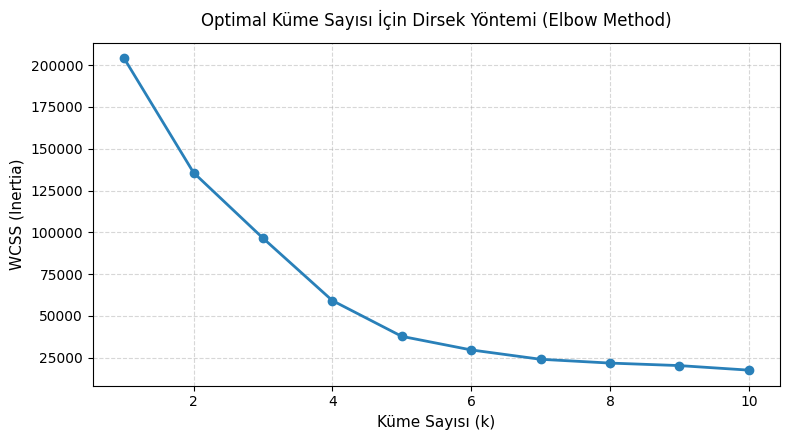

In [7]:
X = df_segmentasyon[['Yillik_Gelir_k$', 'Harcama_Skoru_1_100']]

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 11), wcss, marker='o', color='#2980b9', linewidth=2, markersize=6)
plt.title('Optimal Küme Sayısı İçin Dirsek Yöntemi (Elbow Method)', fontsize=12, pad=12)
plt.xlabel('Küme Sayısı (k)', fontsize=11)
plt.ylabel('WCSS (Inertia)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. K-Means Modeli ile Müşteri Kümelerinin Dağılımı ve Merkez Noktaları
k=5 değeri seçilerek model eğitilmiş, her müşteriye ait segment atanmış ve küme merkezleri (Centroids) işaretlenmiştir.

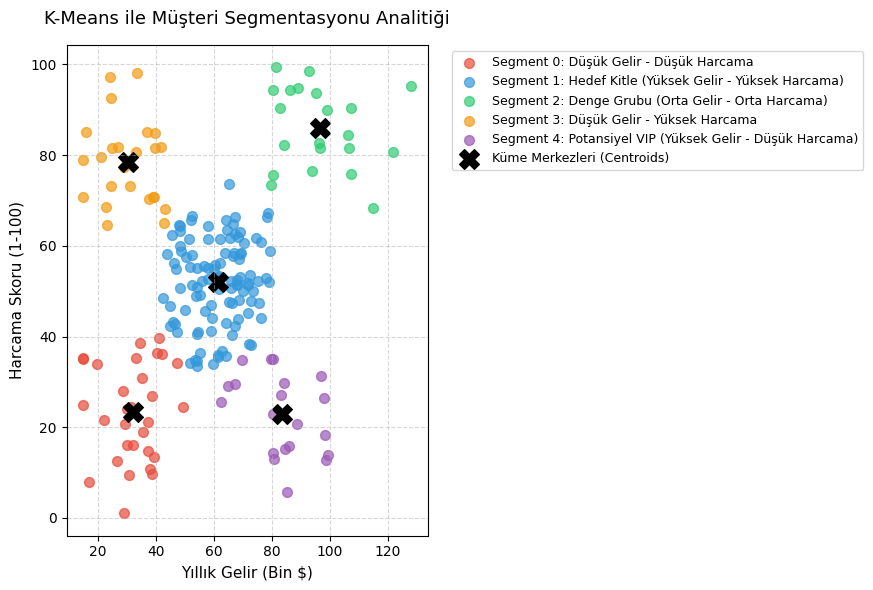

In [8]:
# Modeli eğitme
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
df_segmentasyon['Kume'] = kmeans.fit_predict(X)

# Küme merkezleri
merkezler = kmeans.cluster_centers_

plt.figure(figsize=(9, 6))
renk_paleti = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
kume_isimleri = [
    'Segment 0: Düşük Gelir - Düşük Harcama',
    'Segment 1: Hedef Kitle (Yüksek Gelir - Yüksek Harcama)',
    'Segment 2: Denge Grubu (Orta Gelir - Orta Harcama)',
    'Segment 3: Düşük Gelir - Yüksek Harcama',
    'Segment 4: Potansiyel VIP (Yüksek Gelir - Düşük Harcama)'
]

for i in range(5):
    plt.scatter(
        X.values[df_segmentasyon['Kume'] == i, 0],
        X.values[df_segmentasyon['Kume'] == i, 1],
        s=50,
        c=renk_paleti[i],
        label=kume_isimleri[i],
        alpha=0.7
    )

# Merkez noktaları (X işareti)
plt.scatter(merkezler[:, 0], merkezler[:, 1], s=200, c='black', marker='X', label='Küme Merkezleri (Centroids)')

plt.title('K-Means ile Müşteri Segmentasyonu Analitiği', fontsize=13, pad=15)
plt.xlabel('Yıllık Gelir (Bin $)', fontsize=11)
plt.ylabel('Harcama Skoru (1-100)', fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2.1. Kümeleme Kalitesinin Ölçülmesi (Silhouette Score Analizi)
Optimal küme sayısının matematiksel geçerliliği, noktaların kendi kümesine yakınlığı ve diğer kümelere uzaklığını -1 ile +1 arasında puanlayan Silhouette Skoru ile doğrulanmıştır.

In [9]:
from sklearn.metrics import silhouette_score

sil_skor = silhouette_score(X, df_segmentasyon['Kume'])
print(f"Modelin Silhouette Skoru (k=5 için): {sil_skor:.3f}")

Modelin Silhouette Skoru (k=5 için): 0.493


# 2.2. Segment Bazlı İstatistiksel Profil Özeti
Pazarlama ve bütçe planlamasında kullanılmak üzere her kümenin müşteri sayısı, ortalama geliri ve harcama skoru tablosu çıkarılmıştır.

In [10]:
kume_profili = df_segmentasyon.groupby('Kume').agg(
    Musteri_Sayisi=('Musteri_ID', 'count'),
    Ortalama_Gelir_k=('Yillik_Gelir_k$', 'mean'),
    Ortalama_Harcama_Skoru=('Harcama_Skoru_1_100', 'mean')
).round(1)

kume_profili['Segment_Adi'] = [
    'Düşük Gelir - Düşük Harcama',
    'Hedef Kitle (VIP)',
    'Denge Grubu',
    'Düşük Gelir - Yüksek Harcama',
    'Potansiyel VIP'
]

kume_profili = kume_profili[['Segment_Adi', 'Musteri_Sayisi', 'Ortalama_Gelir_k', 'Ortalama_Harcama_Skoru']]
kume_profili

,Segment_Adi,Musteri_Sayisi,Ortalama_Gelir_k,Ortalama_Harcama_Skoru
Kume,,,,
0,Düşük Gelir - Düşük Harcama,30,32.1,23.4
1,Hedef Kitle (VIP),105,61.4,52.1
2,Denge Grubu,21,96.7,85.9
3,Düşük Gelir - Yüksek Harcama,24,30.3,78.4
4,Potansiyel VIP,20,83.5,22.8


# 3. Müşteri Segmentleri İçin Ticari Aksiyon Planı (Executive Summary)

K-Means gözetimsiz öğrenme modeli sonucunda elde edilen 5 farklı müşteri segmenti için önerilen stratejiler şunlardır:

* **Hedef Kitle (VIP - Yüksek Gelir & Yüksek Harcama):** Şirketin kârlılığını sırtlayan ana gruptur. Lüks ürün lansmanları, özel üyelik avantajları ve kişiye özel müşteri danışmanı atanmalıdır.
* **Potansiyel VIP (Yüksek Gelir & Düşük Harcama):** Yüksek satın alma gücüne sahip olmalarına rağmen mağazaya/platforma az para bırakmaktadırlar. Bu gruba özel çapraz satış (cross-sell) ve kişiselleştirilmiş indirim kampanyaları uygulanmalıdır.
* **Düşük Gelir & Yüksek Harcama (Dürtüsel Tüketiciler):** Fiyat hassasiyetleri yüksektir ancak harcama iştahları fazladır. Taksitli ödeme seçenekleri ve dönemsel 'Flaş İndirim' bildirimleri bu grubu aktif tutacaktır.
* **Denge Grubu (Orta Gelir & Orta Harcama):** En kalabalık tabanı oluşturur. Sadakat puanı sistemleri ve sepeti büyütücü '3 Al 2 Öde' gibi hacim artırıcı promosyonlarla beslenmelidir.